# SQL 与权重分析

用 SQL 汇总各类用户的人数、消费和浏览情况，取出 RFM 得分前 200 名用户。将浏览加权幅度分别设为 0%、10%、20%、30%，比较入选名单、平均消费和浏览得分的变化。


In [1]:
from pathlib import Path
import sqlite3
import pandas as pd

project_dir = Path.cwd()
if project_dir.name == 'code':
    project_dir = project_dir.parent
users = pd.read_csv(project_dir / 'outputs' / 'baseline' / 'user_segments.csv')
connection = sqlite3.connect(':memory:')
users.to_sql('users', connection, index=False, if_exists='replace')

1000

In [2]:
query = """
SELECT
    User_Segment,
    COUNT(*) AS user_count,
    ROUND(AVG(Total_Spending), 2) AS average_spending,
    ROUND(AVG(Purchase_Frequency), 2) AS average_frequency,
    ROUND(AVG(I_Score), 2) AS average_browsing_score
FROM users
GROUP BY User_Segment
ORDER BY user_count DESC;
"""
pd.read_sql_query(query, connection)

,User_Segment,user_count,average_spending,average_frequency,average_browsing_score
0,一般用户,443,2368.12,5.17,48.80
1,一般发展用户,81,1117.95,6.43,49.84
2,重要挽留用户,67,4134.42,2.57,46.53
3,高潜流失客,64,3990.70,4.92,44.09
4,低价值用户,50,1036.52,1.68,42.79
5,重要发展用户,48,3873.96,1.63,48.91
6,重要价值用户,47,3960.19,7.47,42.28
7,一般维持用户,47,1055.40,1.47,45.83
8,重要保持用户,39,4030.23,7.49,48.00
9,隐形活跃者,34,2756.79,1.32,77.99


In [3]:
query = """
WITH ranked AS (
    SELECT
        User_ID,
        User_Segment,
        RFM_Score,
        ROW_NUMBER() OVER (
            ORDER BY RFM_Score DESC, User_ID
        ) AS ranking
    FROM users
)
SELECT *
FROM ranked
WHERE ranking <= 200
ORDER BY ranking;
"""
pd.read_sql_query(query, connection)

,User_ID,User_Segment,RFM_Score,ranking
0,#575,重要价值用户,96.770733,1
1,#203,重要价值用户,93.570405,2
2,#450,重要价值用户,92.494081,3
3,#864,重要价值用户,91.984712,4
4,#607,核心VIP,90.138268,5
...,...,...,...,...
195,#331,一般用户,67.030460,196
196,#641,高潜流失客,66.959280,197
197,#518,一般用户,66.790172,198
198,#113,重要保持用户,66.765763,199


In [4]:
base_ids = set(
    users.sort_values(
        ['RFM_Score', 'User_ID'], ascending=[False, True]
    ).head(200)['User_ID']
)

rows = []
for browsing_weight in [0.0, 0.1, 0.2, 0.3]:
    candidate = users.copy()
    candidate['Trial_Score'] = candidate['RFM_Score'] * (
        1 + browsing_weight * candidate['I_Score'] / 100
    )
    selected = candidate.sort_values(
        ['Trial_Score', 'User_ID'], ascending=[False, True]
    ).head(200)
    selected_ids = set(selected['User_ID'])
    rows.append({
        '浏览加权幅度': browsing_weight,
        '人数': len(selected),
        '与基础名单重合比例': len(base_ids & selected_ids) / len(base_ids),
        '平均累计消费': selected['Total_Spending'].mean(),
        '平均浏览得分': selected['I_Score'].mean(),
    })

weight_comparison = pd.DataFrame(rows)
weight_comparison

,浏览加权幅度,人数,与基础名单重合比例,平均累计消费,平均浏览得分
0,0.0,200,1.000,4117.730,48.832339
1,0.1,200,0.955,4109.840,51.048498
2,0.2,200,0.910,4084.860,53.074435
3,0.3,200,0.880,4045.815,54.757695


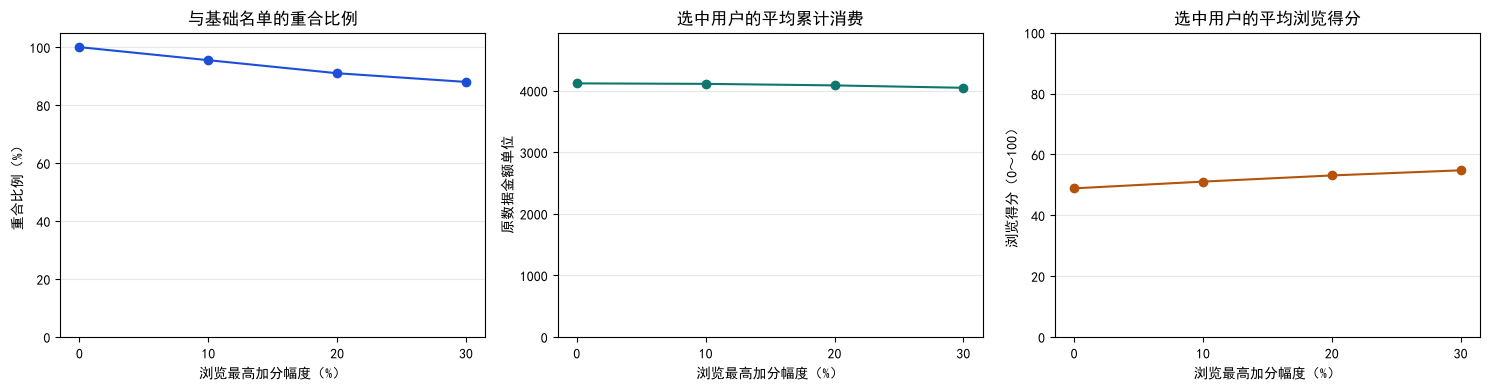

图片已保存到 C:\Users\86156\Documents\ChatGPT\sql\电商用户分层项目_跟做包\outputs\weight_comparison.png


In [5]:
# 绘图设置
import matplotlib.pyplot as plt
from pathlib import Path

# 中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']

plt.rcParams['axes.unicode_minus'] = False

# 加权幅度转为百分比
x = weight_comparison['浏览加权幅度'] * 100

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 名单重合率
axes[0].plot(
    x,
    weight_comparison['与基础名单重合比例'] * 100,
    marker='o',
    color='#1D4ED8'
)

axes[0].set_title('与基础名单的重合比例')
axes[0].set_ylabel('重合比例（%）')
axes[0].set_ylim(0, 105)

# 入选用户的平均累计消费
axes[1].plot(
    x,
    weight_comparison['平均累计消费'],
    marker='o',
    color='#0F766E'
)

axes[1].set_title('选中用户的平均累计消费')
axes[1].set_ylabel('原数据金额单位')
axes[1].set_ylim(
    0,
    weight_comparison['平均累计消费'].max() * 1.2
)

# 入选用户的平均浏览得分
axes[2].plot(
    x,
    weight_comparison['平均浏览得分'],
    marker='o',
    color='#B45309'
)

axes[2].set_title('选中用户的平均浏览得分')
axes[2].set_ylabel('浏览得分（0～100）')
axes[2].set_ylim(0, 100)

for ax in axes:
    ax.set_xlabel('浏览最高加分幅度（%）')
    ax.set_xticks(x)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()

# 保存权重对比图
figure_path = project_dir / 'outputs' / 'weight_comparison.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(figure_path, dpi=160, bbox_inches='tight')

plt.show()

plt.close(fig)

print('图片已保存到', figure_path.resolve())